# 02 - Pemodelan Prioritas Follow-up

**Research question:** apakah model klasifikasi berbasis riwayat aktivitas dapat menentukan prioritas follow-up (Low/Medium/High) lebih baik daripada baseline sederhana?

Protokol: split 80/20 stratified + grouped per customer, tuning dengan StratifiedGroupKFold 5-fold pada data train (scoring macro-F1), model dipilih dari skor CV (bukan test set). Semua logika ada di `src/ml/` (notebook hanya memanggilnya).

> Sel pelatihan di bawah memakan sekitar 2 menit (grid search Random Forest).

In [1]:
import sys
sys.path.append("..")
from IPython.display import display
from src.ml import evaluate as ev
from src.ml import predict as pr
from src.ml.baseline import RULE_DESCRIPTION

res = run = None
from src.ml.train import run_training
res = run_training(write=False)   # tidak menimpa artefak

Data: 1304 baris | train 1041 (319 customer) | test 263 (81 customer) | overlap customer: 0
Logistic Regression: CV macro-F1 0.655 ± 0.035 | params {'C': 0.1}
Random Forest: CV macro-F1 0.644 ± 0.033 | params {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 200}
Model terpilih: Logistic Regression | recall High test 0.691 vs baseline 0.673 -> OK


## 1. Baseline

In [2]:
print(RULE_DESCRIPTION)

High jika attendance_rate_30d < 0.4 atau consecutive_absences >= 3; Medium jika attendance_rate_30d < 0.65 atau consecutive_absences >= 1; selain itu Low.


## 2. Hasil pada test set

,Accuracy,Macro-F1,Recall High,Precision High,F1 High
Model,,,,,
Dummy (kelas terbanyak),0.483,0.217,0.000,0.000,0.000
Baseline rule-based,0.627,0.610,0.673,0.561,0.612
Logistic Regression,0.703,0.670,0.691,0.613,0.650
Random Forest,0.738,0.708,0.673,0.685,0.679


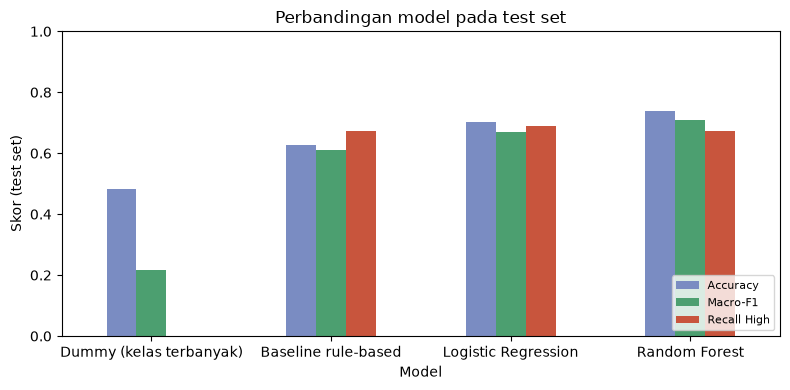

In [3]:
display(ev.comparison_table(res['test_metrics']).round(3))
ev.plot_model_comparison(res['test_metrics']);

In [4]:
print('Model terpilih (berdasar CV macro-F1):', res['chosen'])
print('Syarat recall High >= baseline:', res['guard_ok'])
print('Curiga leakage (akurasi test > 97%):', res['leakage_suspected'])

Model terpilih (berdasar CV macro-F1): Logistic Regression
Syarat recall High >= baseline: True
Curiga leakage (akurasi test > 97%): False


## 3. Confusion matrix dan metrik per kelas

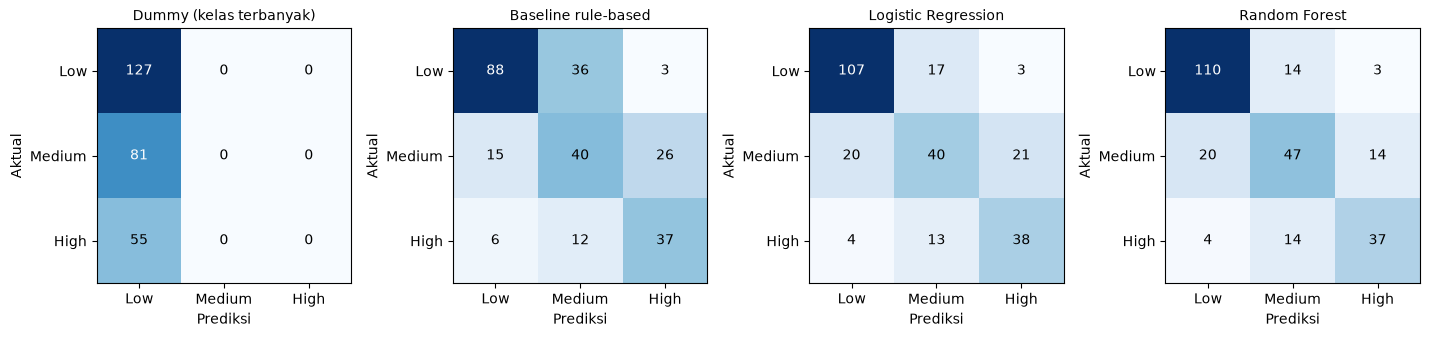

In [5]:
ev.plot_confusion_matrices(res['test_metrics']);

In [6]:
display(ev.per_class_table(res['test_metrics'][res['chosen']]).round(3))

,Precision,Recall,F1,Support
Low,0.817,0.843,0.829,127
Medium,0.571,0.494,0.530,81
High,0.613,0.691,0.650,55


**Interpretasi:** kelas Low paling mudah dikenali, sedangkan **Medium paling sulit** (F1 terendah): wajar karena kelas tengah berada di antara dua batas dan paling terdampak noise serta label yang di-flip. Kesalahan terbesar pada High adalah dikira Medium, bukan dikira Low (customer penting jarang dianggap aman sepenuhnya).

## 4. Gap train vs CV vs test (cek overfitting)

In [7]:
display(res['gap'].round(3))
print(res['best_params'])

,Train macro-F1,CV macro-F1 (train),Test macro-F1
Logistic Regression,0.688,0.655,0.670
Random Forest,0.823,0.644,0.708


{'Logistic Regression': {'C': 0.1}, 'Random Forest': {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 200}}


**Interpretasi:** pada Logistic Regression selisih train, CV, dan test kecil (sekitar 0,03), jadi tidak ada overfitting berat. Random Forest memiliki gap train-CV lebih besar (sekitar 0,18), tanda mulai menghafal data latih, sehingga model sederhana lebih aman pada data sekecil ini.

## 5. Cross-validation 5-fold pada seluruh data (variansi antar fold)

,macro_f1_mean,macro_f1_std,recall_high_mean,recall_high_std
Dummy (kelas terbanyak),0.217,0.001,0.000,0.000
Baseline rule-based,0.565,0.050,0.651,0.067
Logistic Regression,0.666,0.019,0.713,0.064
Random Forest,0.661,0.035,0.636,0.069


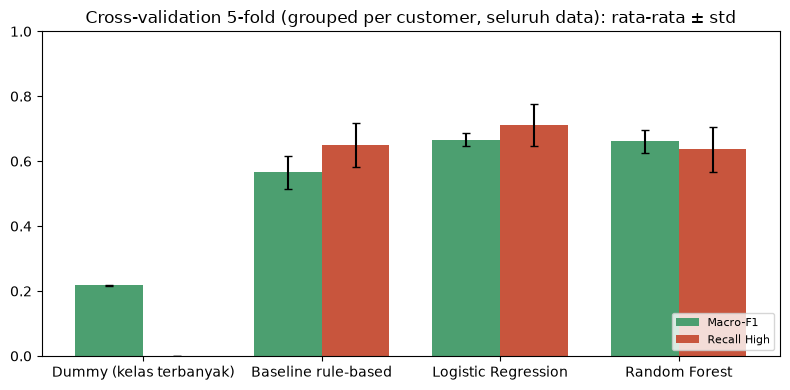

In [8]:
display(res['cv_all'].round(3))
ev.plot_cv_comparison(res['cv_all']);

**Interpretasi:** test set hanya sekitar 260 baris sehingga satu split berfluktuasi. Pada rata-rata lima fold, Logistic Regression dan Random Forest **setara secara statistik** (selisih lebih kecil daripada std), dan keduanya jelas di atas baseline rule-based serta dummy. Karena setara, model yang lebih sederhana dan lebih mudah dijelaskan dipilih.

## 6. Interpretasi model

,feature,importance,std
0,reminder_response_rate,0.0523,0.0211
1,attendance_rate_90d,0.0512,0.0239
2,consecutive_absences,0.0461,0.0139
3,attendance_rate_30d,0.0082,0.0207
4,no_response_streak,0.0055,0.0080
5,absent_count_30d,0.0027,0.0178
6,favorite_class_type,0.0007,0.0023
7,days_since_last_attendance,-0.0050,0.0086
8,reschedule_count_90d,-0.0108,0.0067
9,avg_response_time_hours,-0.0110,0.0136


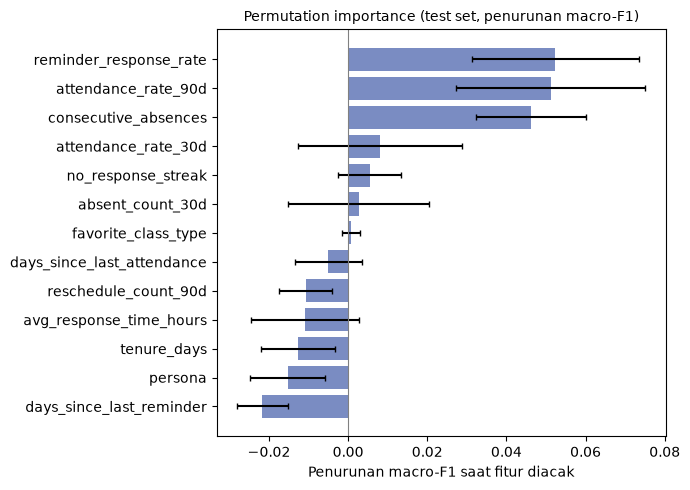

In [9]:
display(res['importance'].round(4).head(10))
ev.plot_permutation_importance(res['importance']);

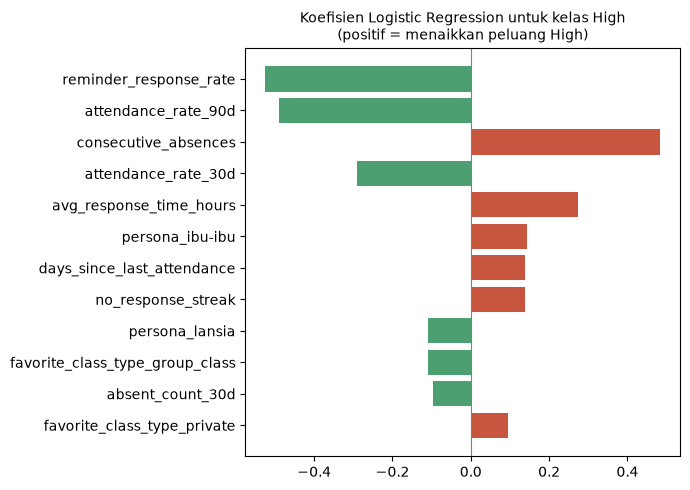

In [10]:
ev.plot_lr_coefficients(res['lr_coef']);

**Interpretasi:** kehadiran (30/90 hari), absen berturut-turut, dan tingkat respons reminder adalah penentu utama, sesuai logika bisnis. Karena fitur kehadiran saling berkorelasi, importance-nya terbagi, jadi nilai kecil pada satu fitur tidak berarti fitur itu tidak berguna. Persona dan tipe kelas hampir tidak menambah informasi.

## 7. Contoh inference (kontrak `predict_priority`)

In [11]:
import pandas as pd

model = pr.LoadedModel(pipeline=res["estimators"][res["chosen"]], metadata={"model_version": "notebook-demo"})
data = pd.read_csv("../data/processed/training_dataset.csv")
sample = data.iloc[res["test_idx"]].query("n_history_events >= 10").sample(8, random_state=1)
for r in sample.to_dict("records"):
    o = pr.predict_priority(r, model)
    print(f"label asli: {r['priority']:<6} | prediksi: {o['priority']:<6} | p(High)={o['probabilities']['High']:.2f} | {o['top_factors']}")

print()
print("Contoh keluaran lengkap predict_priority:")
pr.predict_priority(sample.iloc[0].to_dict(), model)

label asli: Medium | prediksi: Medium | p(High)=0.27 | ['tingkat kehadiran 30 hari: 25%']
label asli: Low    | prediksi: Low    | p(High)=0.03 | []
label asli: Low    | prediksi: Medium | p(High)=0.09 | ['tingkat kehadiran 30 hari: 47%', '3x reschedule dalam 90 hari']
label asli: High   | prediksi: High   | p(High)=0.71 | ['4 absen berturut-turut', 'tingkat kehadiran 30 hari: 25%', '5x reschedule dalam 90 hari']
label asli: Low    | prediksi: Low    | p(High)=0.08 | ['2 reminder terakhir tidak direspons']
label asli: Medium | prediksi: Medium | p(High)=0.29 | ['jarang merespons reminder (33% direspons)']
label asli: Medium | prediksi: High   | p(High)=0.60 | ['3 absen berturut-turut', 'tingkat kehadiran 30 hari: 44%']
label asli: Low    | prediksi: Low    | p(High)=0.02 | []

Contoh keluaran lengkap predict_priority:


{'priority': 'Medium',
 'probabilities': {'Low': 0.1464, 'Medium': 0.5871, 'High': 0.2666},
 'top_factors': ['tingkat kehadiran 30 hari: 25%'],
 'model_version': 'notebook-demo',
 'cold_start': False,
 'note': None}

In [12]:
# Customer baru tanpa riwayat -> cold start
from src.ml.feature_engineering import compute_customer_features
cold = compute_customer_features("lansia", "2026-09-01", None, None, "2026-09-05")
pr.predict_priority(cold, model)

{'priority': 'Low',
 'probabilities': {'Low': 0.4308, 'Medium': 0.4222, 'High': 0.1471},
 'top_factors': [],
 'model_version': 'notebook-demo',
 'cold_start': True,
 'note': 'riwayat belum cukup'}

## Kesimpulan

- Model ML (Logistic Regression/Random Forest) **lebih baik dari baseline rule-based** pada macro-F1, baik di test set maupun rata-rata cross-validation, dan jauh di atas dummy.
- Keunggulan atas baseline **nyata tetapi moderat**; recall High hanya sedikit lebih tinggi daripada baseline. Ini wajar karena data synthetic sengaja mengandung noise dan faktor tersembunyi.
- Hasil ini berasal dari **data synthetic**, jadi hanya menunjukkan bahwa pipeline bekerja, **bukan** klaim akurasi di kondisi nyata Gymnasium.